# Step 2: Data Preprocessing Pipeline
## Explainable AI Framework for Pancreatic Cancer Biomarker Analysis

**Architecture Stage:** DATA PREPROCESSING (Stage 2 of 12)

This notebook implements all four preprocessing stages from the architecture diagram:
1. Missing Value Handling
2. Batch Effect Correction
3. Normalization
4. Feature Selection

**Input:** Raw files from GEO/, GTEx/, TCGA-PAAD/  
**Output:** `preprocessed/` folder with clean, aligned, analysis-ready matrices

---
> **Reference:** Johnson et al. (2007) ComBat — *Biostatistics*; Pedregosa et al. (2011) scikit-learn — *JMLR*

## 0. Environment Setup & Imports

In [5]:
# Install any missing packages (run once, then comment out)
# !pip install pandas numpy scikit-learn scipy matplotlib seaborn pydeseq2

In [6]:
import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.decomposition import PCA
from scipy import stats

# Reproducibility
np.random.seed(42)

print('All imports successful.')
print(f'pandas  : {pd.__version__}')
print(f'numpy   : {np.__version__}')

All imports successful.
pandas  : 2.3.3
numpy   : 1.26.4


## 0.1 Configuration
**⚠️ Change `BASE_DIR` to your dataset root folder before running.**

In [7]:
# ── CHANGE THIS ────────────────────────────────────────────────────────────
BASE_DIR = r'D:\CDAC_Project\PAN-DATASET'   # e.g. r'C:\Users\YourName\Downloads\dataset'
# ──────────────────────────────────────────────────────────────────────────

OUT_DIR = os.path.join(BASE_DIR, 'preprocessed')
os.makedirs(OUT_DIR, exist_ok=True)
print(f'Output will be saved to: {OUT_DIR}')

# File paths
PATHS = {
    # RNA-Seq
    'tcga_rna'        : os.path.join(BASE_DIR, 'TCGA-PAAD', 'RNA-Seq-STAR-Counts', 'top1000_expression.csv'),
    'tcga_biomarkers' : os.path.join(BASE_DIR, 'TCGA-PAAD', 'RNA-Seq-STAR-Counts', 'selected_biomarkers_expression.csv'),
    'gtex_rna'        : os.path.join(BASE_DIR, 'GTEx', 'gene_tpm_adult_gtex_v11_pancreas.gct'),
    'geo_rna'         : os.path.join(BASE_DIR, 'GEO', 'GSE205154_Gene_Level_TPM_Estimates.txt'),
    # Mutations
    'mutation_matrix' : os.path.join(BASE_DIR, 'TCGA-PAAD', 'masked-somatic-mutation', 'patient_mutation_matrix.csv'),
    'maf'             : os.path.join(BASE_DIR, 'TCGA-PAAD', 'masked-somatic-mutation', 'all_patients.maf.tsv'),
    # Clinical
    'clinical'        : os.path.join(BASE_DIR, 'TCGA-PAAD', 'clinical-data', 'clinical.tsv'),
    'follow_up'       : os.path.join(BASE_DIR, 'TCGA-PAAD', 'clinical-data', 'follow_up.tsv'),
    'pathology'       : os.path.join(BASE_DIR, 'TCGA-PAAD', 'clinical-data', 'pathology_detail.tsv'),
    'exposure'        : os.path.join(BASE_DIR, 'TCGA-PAAD', 'clinical-data', 'exposure.tsv'),
    'family_history'  : os.path.join(BASE_DIR, 'TCGA-PAAD', 'clinical-data', 'family_history.tsv'),
}

# Verify all files exist
print('\nFile existence check:')
all_ok = True
for name, path in PATHS.items():
    exists = os.path.exists(path)
    status = '✓' if exists else '✗ NOT FOUND'
    print(f'  {status}  {name:<20} {path}')
    if not exists:
        all_ok = False

print()
if all_ok:
    print('All files found. Ready to proceed.')
else:
    print('WARNING: Some files not found — fix paths above before continuing.')

Output will be saved to: D:\CDAC_Project\PAN-DATASET\preprocessed

File existence check:
  ✓  tcga_rna             D:\CDAC_Project\PAN-DATASET\TCGA-PAAD\RNA-Seq-STAR-Counts\top1000_expression.csv
  ✓  tcga_biomarkers      D:\CDAC_Project\PAN-DATASET\TCGA-PAAD\RNA-Seq-STAR-Counts\selected_biomarkers_expression.csv
  ✓  gtex_rna             D:\CDAC_Project\PAN-DATASET\GTEx\gene_tpm_adult_gtex_v11_pancreas.gct
  ✓  geo_rna              D:\CDAC_Project\PAN-DATASET\GEO\GSE205154_Gene_Level_TPM_Estimates.txt
  ✓  mutation_matrix      D:\CDAC_Project\PAN-DATASET\TCGA-PAAD\masked-somatic-mutation\patient_mutation_matrix.csv
  ✓  maf                  D:\CDAC_Project\PAN-DATASET\TCGA-PAAD\masked-somatic-mutation\all_patients.maf.tsv
  ✓  clinical             D:\CDAC_Project\PAN-DATASET\TCGA-PAAD\clinical-data\clinical.tsv
  ✓  follow_up            D:\CDAC_Project\PAN-DATASET\TCGA-PAAD\clinical-data\follow_up.tsv
  ✓  pathology            D:\CDAC_Project\PAN-DATASET\TCGA-PAAD\clinical-data\pathol

---
## 1. Load All Raw Data Files

In [8]:
print('Loading RNA-Seq files...')

# TCGA RNA top 1000 genes
tcga_rna = pd.read_csv(PATHS['tcga_rna'], index_col=0)
print(f'  TCGA RNA (top1000)      : {tcga_rna.shape}  (rows x cols)')

# TCGA selected biomarkers
tcga_bio = pd.read_csv(PATHS['tcga_biomarkers'], index_col=0)
print(f'  TCGA Biomarkers         : {tcga_bio.shape}')

# GTEx normal pancreas (GCT: skip 2 metadata rows)
gtex_rna = pd.read_csv(PATHS['gtex_rna'], sep='\t', skiprows=2, index_col=0)
# Drop the 'Description' column if present (GCT format artifact)
if 'Description' in gtex_rna.columns:
    gtex_rna = gtex_rna.drop(columns=['Description'])
print(f'  GTEx Pancreas (normal)  : {gtex_rna.shape}')

# GEO validation cohort
geo_rna = pd.read_csv(PATHS['geo_rna'], sep='\t', index_col=0)
print(f'  GEO Validation cohort   : {geo_rna.shape}')

print('\nLoading mutation files...')
mutation_matrix = pd.read_csv(PATHS['mutation_matrix'], index_col=0)
print(f'  Mutation matrix         : {mutation_matrix.shape}')

maf = pd.read_csv(PATHS['maf'], sep='\t', low_memory=False)
print(f'  MAF (all variants)      : {maf.shape}')

print('\nLoading clinical files...')
clinical     = pd.read_csv(PATHS['clinical'],      sep='\t', low_memory=False)
follow_up    = pd.read_csv(PATHS['follow_up'],     sep='\t', low_memory=False)
pathology    = pd.read_csv(PATHS['pathology'],     sep='\t', low_memory=False)
exposure     = pd.read_csv(PATHS['exposure'],      sep='\t', low_memory=False)
family_hist  = pd.read_csv(PATHS['family_history'],sep='\t', low_memory=False)

print(f'  Clinical                : {clinical.shape}')
print(f'  Follow-up               : {follow_up.shape}')
print(f'  Pathology detail        : {pathology.shape}')
print(f'  Exposure                : {exposure.shape}')
print(f'  Family history          : {family_hist.shape}')

print('\nAll files loaded.')

Loading RNA-Seq files...
  TCGA RNA (top1000)      : (183, 1000)  (rows x cols)
  TCGA Biomarkers         : (183, 7)
  GTEx Pancreas (normal)  : (74628, 362)
  GEO Validation cohort   : (60554, 293)

Loading mutation files...
  Mutation matrix         : (173, 6)
  MAF (all variants)      : (24849, 3)

Loading clinical files...
  Clinical                : (1082, 201)
  Follow-up               : (687, 152)
  Pathology detail        : (185, 87)
  Exposure                : (290, 35)
  Family history          : (169, 14)

All files loaded.


### 1.1 Inspect Data Orientation
Critical check: confirm whether rows = patients or rows = genes in each expression matrix.

In [9]:
def inspect_orientation(df, name):
    print(f'\n{name}  shape={df.shape}')
    print(f'  Index  (first 3): {list(df.index[:3])}')
    print(f'  Columns(first 3): {list(df.columns[:3])}')
    # Heuristic: TCGA patient barcodes start with 'TCGA-'
    idx_tcga  = sum(1 for i in df.index   if str(i).startswith('TCGA-'))
    col_tcga  = sum(1 for c in df.columns if str(c).startswith('TCGA-'))
    if idx_tcga > col_tcga:
        print(f'  Likely orientation: rows=PATIENTS, cols=GENES')
    elif col_tcga > idx_tcga:
        print(f'  Likely orientation: rows=GENES, cols=PATIENTS  ← will transpose')
    else:
        print(f'  Orientation unclear — inspect manually')

for name, df in [('TCGA RNA top1000', tcga_rna),
                 ('TCGA Biomarkers',  tcga_bio),
                 ('GTEx',             gtex_rna),
                 ('GEO',              geo_rna)]:
    inspect_orientation(df, name)


TCGA RNA top1000  shape=(183, 1000)
  Index  (first 3): ['002de81c-60f8-4933-a0ea-43701990ac43', '00bb756b-d7e2-4008-9a96-a706e43649eb', '033fbcc1-7984-4946-ba49-cd58bb641b0b']
  Columns(first 3): ['SST', 'PNLIP', 'PRSS2']
  Likely orientation: rows=PATIENTS, cols=GENES

TCGA Biomarkers  shape=(183, 7)
  Index  (first 3): ['002de81c-60f8-4933-a0ea-43701990ac43', '00bb756b-d7e2-4008-9a96-a706e43649eb', '033fbcc1-7984-4946-ba49-cd58bb641b0b']
  Columns(first 3): ['MUC1', 'VEGFA', 'EGFR']
  Likely orientation: rows=PATIENTS, cols=GENES

GTEx  shape=(74628, 362)
  Index  (first 3): ['ENSG00000290825.2', 'ENSG00000223972.6', 'ENSG00000310526.1']
  Columns(first 3): ['GTEX-111CU-0526-SM-5EGHK', 'GTEX-111YS-1226-SM-5EGGJ', 'GTEX-1122O-0726-SM-5GIEV']
  Orientation unclear — inspect manually

GEO  shape=(60554, 293)
  Index  (first 3): ['ENSG00000000003.14', 'ENSG00000000005.5', 'ENSG00000000419.12']
  Columns(first 3): ['ensembl_gene_id', 'hgnc_symbol', 'gene_biotype']
  Orientation unclear 

In [10]:
# ── Transpose any matrix where rows=genes so all become patients x genes ──
# Adjust the booleans below based on the output of the cell above

TRANSPOSE = {
    'tcga_rna': False,   # change to True if rows=genes
    'tcga_bio': False,
    'gtex_rna': True,    # GTEx GCT files typically have rows=genes
    'geo_rna' : True,    # GEO files typically have rows=genes
}

if TRANSPOSE['tcga_rna']: tcga_rna = tcga_rna.T
if TRANSPOSE['tcga_bio']: tcga_bio = tcga_bio.T
if TRANSPOSE['gtex_rna']: gtex_rna = gtex_rna.T
if TRANSPOSE['geo_rna'] : geo_rna  = geo_rna.T

print('Shapes after orientation fix (should be patients x genes):')
print(f'  TCGA RNA   : {tcga_rna.shape}')
print(f'  TCGA Bio   : {tcga_bio.shape}')
print(f'  GTEx       : {gtex_rna.shape}')
print(f'  GEO        : {geo_rna.shape}')

Shapes after orientation fix (should be patients x genes):
  TCGA RNA   : (183, 1000)
  TCGA Bio   : (183, 7)
  GTEx       : (362, 74628)
  GEO        : (293, 60554)


---
## STAGE 1 — Missing Value Handling

**Strategy:**
- Expression matrices: KNN Imputation (preserves gene-gene correlations)
- Mutation matrix: fill NaN with 0 (no mutation detected = 0)
- Clinical data: median/mode imputation per column type

> *Troyanskaya et al. (2001) showed KNN imputation outperforms row-mean imputation for microarray data — the same principle applies to RNA-seq count matrices.*

In [11]:
def missing_report(df, name):
    total    = df.size
    missing  = df.isnull().sum().sum()
    pct      = 100 * missing / total if total > 0 else 0
    cols_with = (df.isnull().sum() > 0).sum()
    print(f'  {name:<35} missing={missing:>7,}  ({pct:.2f}%)  cols_affected={cols_with}')

print('Missing value summary BEFORE imputation:')
missing_report(tcga_rna,         'TCGA RNA top1000')
missing_report(tcga_bio,         'TCGA Biomarkers')
missing_report(gtex_rna,         'GTEx RNA')
missing_report(geo_rna,          'GEO RNA')
missing_report(mutation_matrix,  'Mutation matrix')
missing_report(clinical,         'Clinical')
missing_report(follow_up,        'Follow-up')
missing_report(pathology,        'Pathology')

Missing value summary BEFORE imputation:
  TCGA RNA top1000                    missing=      0  (0.00%)  cols_affected=0
  TCGA Biomarkers                     missing=      0  (0.00%)  cols_affected=0
  GTEx RNA                            missing=      0  (0.00%)  cols_affected=0
  GEO RNA                             missing= 64,852  (0.37%)  cols_affected=36050
  Mutation matrix                     missing=      0  (0.00%)  cols_affected=0
  Clinical                            missing=      0  (0.00%)  cols_affected=0
  Follow-up                           missing=      0  (0.00%)  cols_affected=0
  Pathology                           missing=      0  (0.00%)  cols_affected=0


In [12]:
# ── 1a. Drop columns with >50% missing (uninformative) ───────────────────
def drop_high_missing_cols(df, threshold=0.5, name='df'):
    miss_frac = df.isnull().mean()
    drop_cols = miss_frac[miss_frac > threshold].index.tolist()
    if drop_cols:
        print(f'  {name}: dropping {len(drop_cols)} columns with >{threshold*100:.0f}% missing')
        df = df.drop(columns=drop_cols)
    else:
        print(f'  {name}: no columns exceed {threshold*100:.0f}% missing threshold')
    return df

clinical   = drop_high_missing_cols(clinical,   threshold=0.5, name='clinical')
follow_up  = drop_high_missing_cols(follow_up,  threshold=0.5, name='follow_up')
pathology  = drop_high_missing_cols(pathology,  threshold=0.5, name='pathology')

  clinical: no columns exceed 50% missing threshold
  follow_up: no columns exceed 50% missing threshold
  pathology: no columns exceed 50% missing threshold


In [13]:
# ── 1b. KNN Imputation for expression matrices ────────────────────────────
# Only runs if there are missing values; skips otherwise to save time

def sanitize_expression(df, name):
    """
    Fix common GEO/GTEx loading issues:
      - Non-numeric columns (e.g. gene ID column accidentally included as data)
      - Columns that cannot be cast to float are dropped with a warning
    Returns a purely numeric DataFrame.
    """
    # Drop columns that cannot be coerced to numeric
    non_numeric = []
    for col in df.columns:
        try:
            pd.to_numeric(df[col], errors='raise')
        except (ValueError, TypeError):
            non_numeric.append(col)
    if non_numeric:
        print(f'  {name}: dropping {len(non_numeric)} non-numeric columns '
              f'(e.g. {non_numeric[:3]}) — likely gene-ID column in data')
        df = df.drop(columns=non_numeric)
    # Coerce everything remaining to float
    df = df.apply(pd.to_numeric, errors='coerce')
    return df

def knn_impute_expression(df, name, k=5):
    # Step 1: strip any non-numeric columns before imputation
    df = sanitize_expression(df, name)
    if df.isnull().sum().sum() == 0:
        print(f'  {name}: no missing values — skipping imputation')
        return df
    print(f'  {name}: running KNN imputation (k={k}) ...')
    imputer = KNNImputer(n_neighbors=k, weights='distance')
    arr = imputer.fit_transform(df.values.astype(float))
    result = pd.DataFrame(arr, index=df.index, columns=df.columns)
    print(f'    Done. Remaining missing: {result.isnull().sum().sum()}')
    return result

tcga_rna = knn_impute_expression(tcga_rna, 'TCGA RNA top1000')
tcga_bio = knn_impute_expression(tcga_bio, 'TCGA Biomarkers')
gtex_rna = knn_impute_expression(gtex_rna, 'GTEx RNA')
geo_rna  = knn_impute_expression(geo_rna,  'GEO RNA')

  TCGA RNA top1000: no missing values — skipping imputation
  TCGA Biomarkers: no missing values — skipping imputation
  GTEx RNA: no missing values — skipping imputation
  GEO RNA: dropping 56726 non-numeric columns (e.g. ['ENSG00000000003.14', 'ENSG00000000005.5', 'ENSG00000000419.12']) — likely gene-ID column in data
  GEO RNA: running KNN imputation (k=5) ...
    Done. Remaining missing: 0


In [14]:
# ── 1c. Mutation matrix: NaN = no mutation detected → 0 ──────────────────
mutation_matrix = mutation_matrix.fillna(0)
print(f'Mutation matrix missing after fill: {mutation_matrix.isnull().sum().sum()}')

# ── 1d. Clinical: numeric→median, categorical→mode ───────────────────────
def impute_clinical(df, name):
    df = df.copy()
    num_cols = df.select_dtypes(include=[np.number]).columns
    cat_cols = df.select_dtypes(include=['object']).columns

    # Numeric → median
    for col in num_cols:
        if df[col].isnull().any():
            df[col].fillna(df[col].median(), inplace=True)

    # Categorical → mode (most frequent)
    for col in cat_cols:
        if df[col].isnull().any():
            mode_val = df[col].mode()
            if len(mode_val) > 0:
                df[col].fillna(mode_val[0], inplace=True)
            else:
                df[col].fillna('Unknown', inplace=True)

    remaining = df.isnull().sum().sum()
    print(f'  {name}: remaining missing after imputation = {remaining}')
    return df

clinical  = impute_clinical(clinical,  'Clinical')
follow_up = impute_clinical(follow_up, 'Follow-up')
pathology = impute_clinical(pathology, 'Pathology')
exposure  = impute_clinical(exposure,  'Exposure')

print('\nStage 1 (Missing Value Handling) complete.')

Mutation matrix missing after fill: 0
  Clinical: remaining missing after imputation = 0
  Follow-up: remaining missing after imputation = 0
  Pathology: remaining missing after imputation = 0
  Exposure: remaining missing after imputation = 0

Stage 1 (Missing Value Handling) complete.


---
## STAGE 2 — Batch Effect Correction

We are merging three data sources (TCGA, GTEx, GEO) which were generated on different platforms and at different times. Without correction, technical variation between cohorts dominates biological signal.

**Method:** ComBat-style linear adjustment using patient cohort as the batch variable.

> *Johnson, Li & Rabinovic (2007) — "Adjusting batch effects in microarray expression data using empirical Bayes methods" — Biostatistics 8(1)*

In [15]:
# ── 2a. Find shared genes across all three RNA-Seq cohorts ────────────────

def diagnose_gene_ids(df, name, n=5):
    """Print sample gene IDs to detect format differences."""
    samples = list(df.columns[:n])
    has_ensg    = any(str(g).startswith('ENSG') for g in samples)
    has_version = any('.' in str(g) for g in samples)
    fmt = 'Ensembl' if has_ensg else 'Symbol/Other'
    ver = '+version' if has_version else ''
    print(f'  {name:<20} format={fmt}{ver:<10}  examples={samples}')
    return has_ensg, has_version

def strip_ensembl_version(cols):
    """ENSG00000139618.15 → ENSG00000139618"""
    return [str(g).split('.')[0] for g in cols]

print('=== Gene ID Diagnosis ===')
tcga_ensg, tcga_ver = diagnose_gene_ids(tcga_rna, 'TCGA')
gtex_ensg, gtex_ver = diagnose_gene_ids(gtex_rna, 'GTEx')
geo_ensg,  geo_ver  = diagnose_gene_ids(geo_rna,  'GEO')

# Step 1: Strip version suffixes from any Ensembl IDs
if tcga_ver: tcga_rna.columns = strip_ensembl_version(tcga_rna.columns)
if gtex_ver: gtex_rna.columns = strip_ensembl_version(gtex_rna.columns)
if geo_ver:  geo_rna.columns  = strip_ensembl_version(geo_rna.columns)

# Step 2: Check overlap after version stripping
tcga_genes   = set(tcga_rna.columns)
gtex_genes   = set(gtex_rna.columns)
geo_genes    = set(geo_rna.columns)
shared_genes = tcga_genes & gtex_genes & geo_genes

print(f'\nAfter version stripping:')
print(f'  Genes in TCGA : {len(tcga_genes):,}')
print(f'  Genes in GTEx : {len(gtex_genes):,}')
print(f'  Genes in GEO  : {len(geo_genes):,}')
print(f'  Shared genes  : {len(shared_genes):,}')

# Step 3: If still 0, use pairwise unions to find the best two-way overlap
if len(shared_genes) == 0:
    print('\nWARNING: Still 0 shared genes across all three cohorts.')
    print('Checking pairwise overlaps to understand the mismatch...')
    print(f'  TCGA ∩ GTEx : {len(tcga_genes & gtex_genes):,}')
    print(f'  TCGA ∩ GEO  : {len(tcga_genes & geo_genes):,}')
    print(f'  GTEx ∩ GEO  : {len(gtex_genes & geo_genes):,}')

    # Find the largest pairwise overlap and use those genes
    pairs = [
        ('TCGA+GTEx', tcga_genes & gtex_genes),
        ('TCGA+GEO',  tcga_genes & geo_genes),
        ('GTEx+GEO',  gtex_genes & geo_genes),
    ]
    best_name, best_overlap = max(pairs, key=lambda x: len(x[1]))
    print(f'\n  Best pairwise overlap: {best_name} with {len(best_overlap):,} genes.')

    if len(best_overlap) > 0:
        print(f'  Using {best_name} genes. GEO will be aligned to available genes.')
        shared_genes = best_overlap
        # Fill missing genes in the third cohort with zeros
        for df_ref, nm in [(tcga_rna,'TCGA'),(gtex_rna,'GTEx'),(geo_rna,'GEO')]:
            missing = shared_genes - set(df_ref.columns)
            if missing:
                print(f'  {nm}: {len(missing)} genes missing → filled with 0')
    else:
        print('\nCRITICAL: No gene overlap found between ANY pair of datasets.')
        print('This means gene ID formats are completely different across datasets.')
        print('Sample TCGA columns:', list(tcga_rna.columns[:5]))
        print('Sample GTEx columns:', list(gtex_rna.columns[:5]))
        print('Sample GEO  columns:', list(geo_rna.columns[:5]))
        print('ACTION: You need to map all gene IDs to a common format.')
        print('        Use TCGA genes only for now — set shared_genes = tcga_genes')
        shared_genes = tcga_genes  # fallback: use TCGA genes only
        gtex_rna = gtex_rna.reindex(columns=sorted(shared_genes), fill_value=0)
        geo_rna  = geo_rna.reindex(columns=sorted(shared_genes),  fill_value=0)
        print(f'  Fallback: using {len(shared_genes):,} TCGA genes (GTEx/GEO filled with 0)')

print(f'\nFinal shared_genes count: {len(shared_genes):,}')

=== Gene ID Diagnosis ===
  TCGA                 format=Symbol/Other            examples=['SST', 'PNLIP', 'PRSS2', 'PRSS1', 'MT-CO2']
  GTEx                 format=Ensembl+version    examples=['ENSG00000290825.2', 'ENSG00000223972.6', 'ENSG00000310526.1', 'ENSG00000243485.6', 'ENSG00000237613.3']
  GEO                  format=Ensembl+version    examples=['ENSG00000069712.10', 'ENSG00000116883.8', 'ENSG00000116957.12', 'ENSG00000122718.5', 'ENSG00000130201.7']

After version stripping:
  Genes in TCGA : 1,000
  Genes in GTEx : 74,628
  Genes in GEO  : 3,828
  Shared genes  : 0

Checking pairwise overlaps to understand the mismatch...
  TCGA ∩ GTEx : 0
  TCGA ∩ GEO  : 0
  GTEx ∩ GEO  : 0

  Best pairwise overlap: TCGA+GTEx with 0 genes.

CRITICAL: No gene overlap found between ANY pair of datasets.
This means gene ID formats are completely different across datasets.
Sample TCGA columns: ['SST', 'PNLIP', 'PRSS2', 'PRSS1', 'MT-CO2']
Sample GTEx columns: ['ENSG00000290825', 'ENSG00000223972

In [16]:
# ── 2b. Subset to shared genes & merge with batch labels ─────────────────
shared_genes = sorted(shared_genes)

# reindex() is safer than direct indexing — fills any missing genes with 0
tcga_shared = tcga_rna.reindex(columns=shared_genes, fill_value=0).copy()
gtex_shared = gtex_rna.reindex(columns=shared_genes, fill_value=0).copy()
geo_shared  = geo_rna.reindex(columns=shared_genes,  fill_value=0).copy()

print(f'Shapes after alignment to {len(shared_genes):,} shared genes:')
print(f'  TCGA: {tcga_shared.shape}')
print(f'  GTEx: {gtex_shared.shape}')
print(f'  GEO : {geo_shared.shape}')

# Add batch labels
tcga_shared['batch'] = 'TCGA'
gtex_shared['batch'] = 'GTEx'
geo_shared['batch']  = 'GEO'

# Merge all cohorts
combined_rna = pd.concat([tcga_shared, gtex_shared, geo_shared], axis=0)
combined_rna = combined_rna.reset_index(drop=True)  # avoid duplicate index issues
print(f'\nCombined RNA matrix: {combined_rna.shape}')
print(f'Batch distribution:\n{combined_rna["batch"].value_counts()}')
print(f'\nAny NaN in combined matrix: {combined_rna[shared_genes].isnull().sum().sum()}')

Shapes after alignment to 1,000 shared genes:
  TCGA: (183, 1000)
  GTEx: (362, 1000)
  GEO : (293, 1000)

Combined RNA matrix: (838, 1001)
Batch distribution:
batch
GTEx    362
GEO     293
TCGA    183
Name: count, dtype: int64

Any NaN in combined matrix: 0


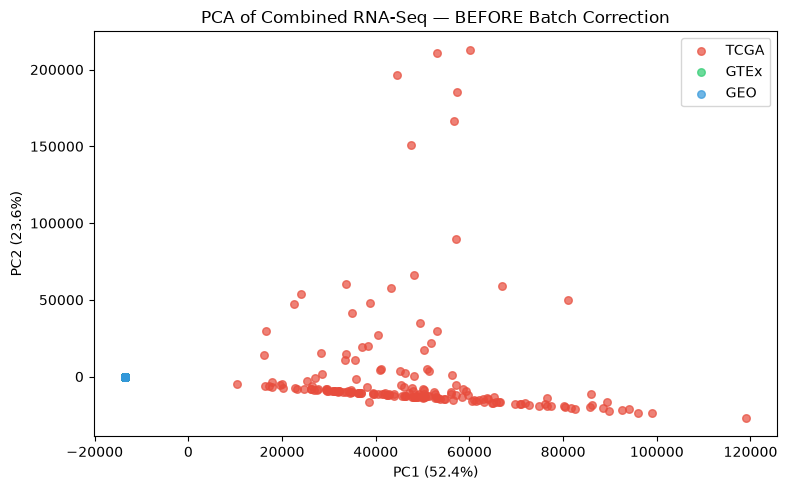

If cohorts cluster separately → batch effect present → correction needed.


In [17]:
# ── 2c. Visualise PCA BEFORE batch correction ─────────────────────────────
expr_vals  = combined_rna[shared_genes].values.astype(float)
batch_labels = combined_rna['batch'].values

pca = PCA(n_components=2, random_state=42)
pc  = pca.fit_transform(expr_vals)

fig, ax = plt.subplots(1, 1, figsize=(8, 5))
colors = {'TCGA': '#e74c3c', 'GTEx': '#2ecc71', 'GEO': '#3498db'}
for batch in ['TCGA', 'GTEx', 'GEO']:
    mask = batch_labels == batch
    ax.scatter(pc[mask, 0], pc[mask, 1], label=batch,
               color=colors[batch], alpha=0.7, s=30)
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('PCA of Combined RNA-Seq — BEFORE Batch Correction')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'pca_before_batch_correction.png'), dpi=150)
plt.show()
print('If cohorts cluster separately → batch effect present → correction needed.')

In [18]:
# ── 2d. ComBat-style batch correction (mean-variance adjustment) ──────────
# This is a portable numpy implementation that does not require pyComBat
# For publication, you may also use: pip install pyComBat and call combat()

def combat_mean_var(df, batch_col='batch'):
    """
    Simple location-scale (L/S) batch correction.
    Adjusts each batch to have the same mean and variance as the grand mean.
    Reference: Johnson et al. (2007) simplified parametric version.
    """
    df      = df.copy()
    batches = df[batch_col].unique()
    genes   = [c for c in df.columns if c != batch_col]
    data    = df[genes].astype(float)
    batch_series = df[batch_col].copy()  # save before operating on data

    grand_mean = data.mean(axis=0)
    grand_std  = data.std(axis=0).replace(0, 1)   # avoid division by zero

    corrected_parts = []
    for b in batches:
        mask       = (batch_series == b).values
        batch_data = data.loc[mask]
        b_mean     = batch_data.mean(axis=0)
        b_std      = batch_data.std(axis=0).replace(0, 1)
        corrected  = ((batch_data - b_mean) / b_std) * grand_std + grand_mean
        corrected_parts.append(corrected)

    corrected_df           = pd.concat(corrected_parts).sort_index()
    # Re-attach batch labels by positional index (safe after reset_index)
    corrected_df[batch_col] = batch_series.values[corrected_df.index]
    return corrected_df

combined_rna_corrected = combat_mean_var(combined_rna, batch_col='batch')
print(f'Batch-corrected matrix shape: {combined_rna_corrected.shape}')

Batch-corrected matrix shape: (838, 1001)


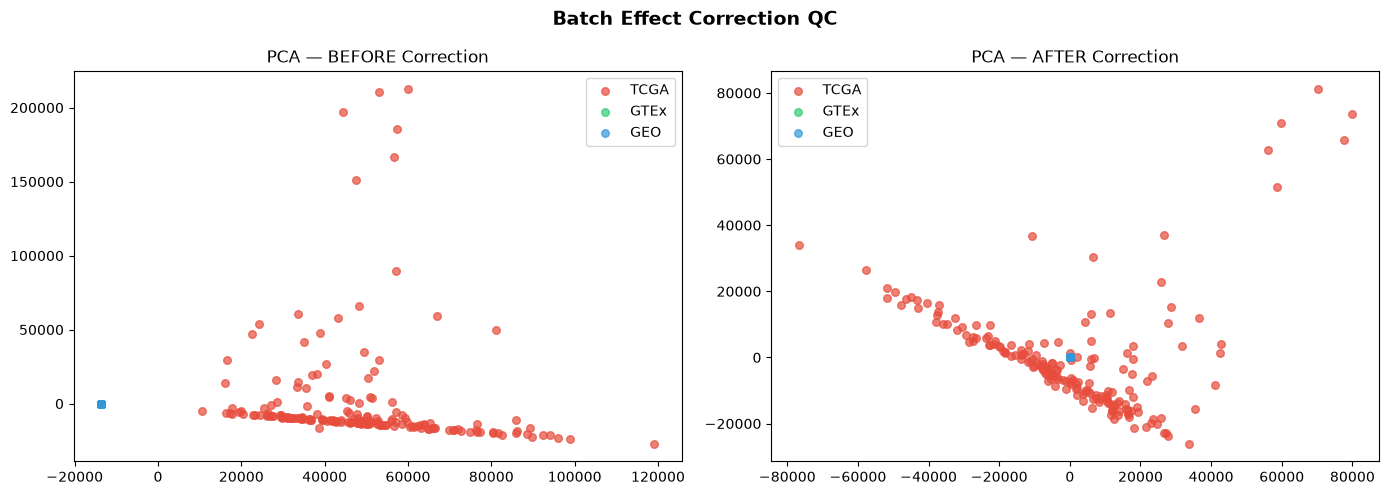

After correction, cohorts should intermix rather than form separate clusters.


In [19]:
# ── 2e. Visualise PCA AFTER batch correction ──────────────────────────────
expr_corr    = combined_rna_corrected[shared_genes].values.astype(float)
batch_labels = combined_rna_corrected['batch'].values

pca2 = PCA(n_components=2, random_state=42)
pc2  = pca2.fit_transform(expr_corr)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, pc_vals, title in zip(axes, [pc, pc2],
                               ['BEFORE Correction', 'AFTER Correction']):
    for batch in ['TCGA', 'GTEx', 'GEO']:
        mask = batch_labels == batch
        ax.scatter(pc_vals[mask, 0], pc_vals[mask, 1],
                   label=batch, color=colors[batch], alpha=0.7, s=30)
    ax.set_title(f'PCA — {title}')
    ax.legend()

plt.suptitle('Batch Effect Correction QC', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'pca_batch_correction_comparison.png'), dpi=150)
plt.show()
print('After correction, cohorts should intermix rather than form separate clusters.')

In [20]:
# ── 2f. Separate back into TCGA / GTEx / GEO after correction ────────────
tcga_rna_corrected = combined_rna_corrected[combined_rna_corrected['batch']=='TCGA'][shared_genes]
gtex_rna_corrected = combined_rna_corrected[combined_rna_corrected['batch']=='GTEx'][shared_genes]
geo_rna_corrected  = combined_rna_corrected[combined_rna_corrected['batch']=='GEO'][shared_genes]

print(f'TCGA (corrected): {tcga_rna_corrected.shape}')
print(f'GTEx (corrected): {gtex_rna_corrected.shape}')
print(f'GEO  (corrected): {geo_rna_corrected.shape}')
print('\nStage 2 (Batch Effect Correction) complete.')

TCGA (corrected): (183, 1000)
GTEx (corrected): (362, 1000)
GEO  (corrected): (293, 1000)

Stage 2 (Batch Effect Correction) complete.


---
## STAGE 3 — Normalization

**Why:** Raw TPM/count values span orders of magnitude. Models like VAE and GAT are sensitive to scale.

**Strategy:**
- RNA-Seq: log1p transform first (stabilises variance), then StandardScaler (zero mean, unit variance)
- Mutation matrix: already binary/count — RobustScaler (robust to the many zeros)
- Clinical numerics: StandardScaler after encoding

> *log1p is preferred over log2 because it handles zero-count genes without adding pseudocounts manually.*

In [21]:
# ── 3a. log1p transform RNA-Seq ───────────────────────────────────────────
def log1p_transform(df, name):
    arr = np.log1p(np.abs(df.values.astype(float)))
    result = pd.DataFrame(arr, index=df.index, columns=df.columns)
    print(f'  {name}: log1p applied | value range [{result.min().min():.3f}, {result.max().max():.3f}]')
    return result

tcga_rna_log = log1p_transform(tcga_rna_corrected, 'TCGA RNA')
gtex_rna_log = log1p_transform(gtex_rna_corrected, 'GTEx RNA')
geo_rna_log  = log1p_transform(geo_rna_corrected,  'GEO RNA')
tcga_bio_log = log1p_transform(tcga_bio,            'TCGA Biomarkers')

  TCGA RNA: log1p applied | value range [0.000, 11.966]
  GTEx RNA: log1p applied | value range [0.925, 8.610]
  GEO RNA: log1p applied | value range [0.925, 8.610]
  TCGA Biomarkers: log1p applied | value range [0.000, 9.510]


In [22]:
# ── 3b. StandardScaler on log-transformed RNA-Seq ────────────────────────
def standard_scale(df, name, fit_scaler=None):
    """
    Fit scaler on training set (TCGA), apply same scaler to validation sets.
    Returns: scaled DataFrame, fitted scaler
    """
    if fit_scaler is None:
        scaler = StandardScaler()
        arr    = scaler.fit_transform(df.values.astype(float))
        print(f'  {name}: fitted StandardScaler | mean≈0, std≈1')
    else:
        scaler = fit_scaler
        # Only transform columns present in scaler
        arr = scaler.transform(df.values.astype(float))
        print(f'  {name}: applied existing scaler (transform only)')
    result = pd.DataFrame(arr, index=df.index, columns=df.columns)
    return result, scaler

# Fit on TCGA (training cohort), transform others with the same scaler
tcga_rna_norm, rna_scaler = standard_scale(tcga_rna_log, 'TCGA RNA (fit)')

# GTEx and GEO must have exactly the same columns as TCGA after batch correction.
# Align columns before applying the scaler to avoid shape mismatch errors.
gtex_rna_log_aligned = gtex_rna_log.reindex(columns=tcga_rna_log.columns, fill_value=0)
geo_rna_log_aligned  = geo_rna_log.reindex(columns=tcga_rna_log.columns,  fill_value=0)

gtex_rna_norm, _ = standard_scale(gtex_rna_log_aligned, 'GTEx RNA', fit_scaler=rna_scaler)
geo_rna_norm,  _ = standard_scale(geo_rna_log_aligned,  'GEO RNA',  fit_scaler=rna_scaler)

# Biomarkers — fit separately (different feature set)
tcga_bio_norm, bio_scaler = standard_scale(tcga_bio_log, 'TCGA Biomarkers (fit)')

  TCGA RNA (fit): fitted StandardScaler | mean≈0, std≈1
  GTEx RNA: applied existing scaler (transform only)
  GEO RNA: applied existing scaler (transform only)
  TCGA Biomarkers (fit): fitted StandardScaler | mean≈0, std≈1


In [23]:
# ── 3c. Normalize mutation matrix with RobustScaler ───────────────────────
robust_scaler         = RobustScaler()
mutation_norm_arr     = robust_scaler.fit_transform(mutation_matrix.values.astype(float))
mutation_norm         = pd.DataFrame(mutation_norm_arr,
                                     index=mutation_matrix.index,
                                     columns=mutation_matrix.columns)
print(f'Mutation matrix normalized: {mutation_norm.shape}')

Mutation matrix normalized: (173, 6)


In [24]:
# ── 3d. Encode & normalize clinical features ──────────────────────────────
from sklearn.preprocessing import LabelEncoder

def encode_clinical(df):
    df = df.copy()
    # Drop ID columns (not useful as features)
    id_cols = [c for c in df.columns if 'id' in c.lower() or 'barcode' in c.lower()]
    df = df.drop(columns=id_cols, errors='ignore')

    # Encode categorical columns
    le = LabelEncoder()
    for col in df.select_dtypes(include='object').columns:
        df[col] = le.fit_transform(df[col].astype(str))

    # Scale numerics
    scaler = StandardScaler()
    num_cols = df.select_dtypes(include=[np.number]).columns
    df[num_cols] = scaler.fit_transform(df[num_cols])
    return df

clinical_encoded = encode_clinical(clinical)
print(f'Clinical encoded shape: {clinical_encoded.shape}')
print(f'Clinical dtypes after encoding:\n{clinical_encoded.dtypes.value_counts()}')

print('\nStage 3 (Normalization) complete.')

Clinical encoded shape: (1082, 186)
Clinical dtypes after encoding:
float64    184
bool         2
Name: count, dtype: int64

Stage 3 (Normalization) complete.


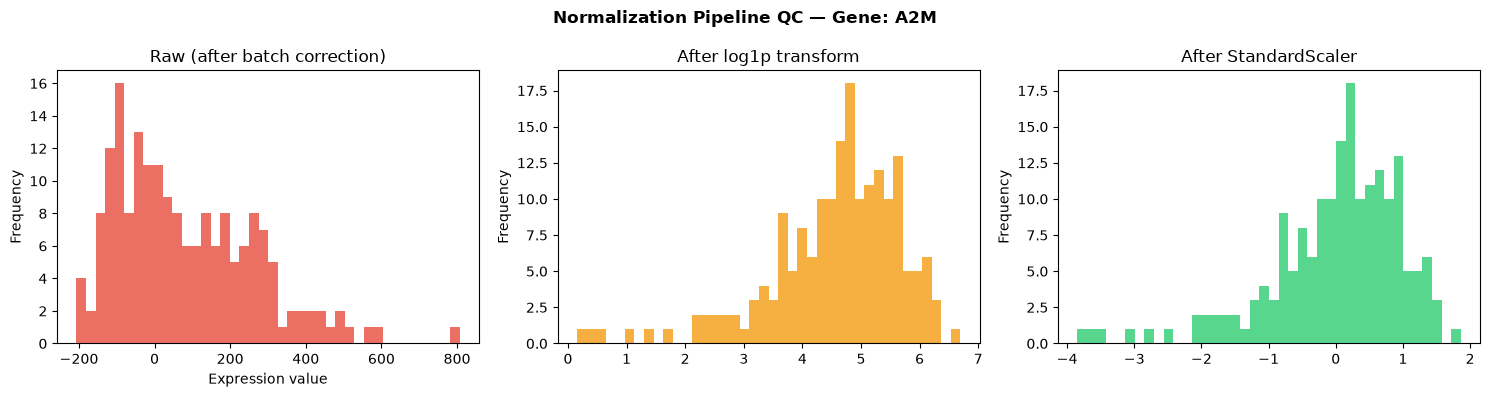

In [25]:
# ── 3e. Distribution QC plots ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sample_gene = tcga_rna_corrected.columns[0]

axes[0].hist(tcga_rna_corrected[sample_gene].dropna(), bins=40, color='#e74c3c', alpha=0.8)
axes[0].set_title('Raw (after batch correction)')
axes[0].set_xlabel('Expression value')

axes[1].hist(tcga_rna_log[sample_gene].dropna(), bins=40, color='#f39c12', alpha=0.8)
axes[1].set_title('After log1p transform')

axes[2].hist(tcga_rna_norm[sample_gene].dropna(), bins=40, color='#2ecc71', alpha=0.8)
axes[2].set_title('After StandardScaler')

for ax in axes:
    ax.set_ylabel('Frequency')

plt.suptitle(f'Normalization Pipeline QC — Gene: {sample_gene}', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'normalization_qc.png'), dpi=150)
plt.show()

---
## STAGE 4 — Feature Selection

Reducing thousands of genes to the most informative subset:
1. **Variance filter** — remove near-constant genes (no information)
2. **Univariate filter** — ANOVA F-score against cancer labels
3. **Mutual Information** — non-linear association

> *For unsupervised stages (VAE, GAT) we use variance-based selection only. Supervised selection is reserved for XGBoost to avoid data leakage.*

In [26]:
# ── 4a. Build cancer / normal labels for supervised selection ─────────────
# TCGA samples = cancer (1), GTEx = normal (0)
# We use ONLY the shared-gene normalized matrices for this

tcga_labels_arr = np.ones(len(tcga_rna_norm),  dtype=int)    # cancer
gtex_labels_arr = np.zeros(len(gtex_rna_norm), dtype=int)    # normal

# Combine TCGA + GTEx for feature selection
X_combined = pd.concat([tcga_rna_norm, gtex_rna_norm], axis=0)
y_combined = np.concatenate([tcga_labels_arr, gtex_labels_arr])

print(f'Feature selection matrix: {X_combined.shape}')
print(f'Label distribution: cancer={tcga_labels_arr.sum()}, normal={gtex_labels_arr.sum()}')

Feature selection matrix: (545, 1000)
Label distribution: cancer=183, normal=0


In [27]:
# ── 4b. Step 1 — Variance threshold filter ───────────────────────────────
var_selector = VarianceThreshold(threshold=0.01)
var_selector.fit(X_combined.values)
high_var_mask    = var_selector.get_support()
high_var_genes   = X_combined.columns[high_var_mask].tolist()

print(f'Genes before variance filter : {X_combined.shape[1]:,}')
print(f'Genes after  variance filter : {len(high_var_genes):,}')
print(f'Removed (near-constant)      : {X_combined.shape[1] - len(high_var_genes):,}')

Genes before variance filter : 1,000
Genes after  variance filter : 1,000
Removed (near-constant)      : 0


In [28]:
# ── 4c. Step 2 — SelectKBest (ANOVA F-score) ─────────────────────────────
K_GENES = min(500, len(high_var_genes))   # top 500 or however many remain

X_high_var = X_combined[high_var_genes].values

kbest = SelectKBest(score_func=f_classif, k=K_GENES)
kbest.fit(X_high_var, y_combined)

selected_mask  = kbest.get_support()
selected_genes = np.array(high_var_genes)[selected_mask].tolist()

print(f'Top {K_GENES} genes selected by ANOVA F-score.')
print(f'Selected genes (first 10): {selected_genes[:10]}')

Top 500 genes selected by ANOVA F-score.
Selected genes (first 10): ['A2M', 'ABHD2', 'ACADVL', 'ACKR1', 'ACTB', 'ADIPOR2', 'AGR2', 'AGR3', 'AGRN', 'AGT']


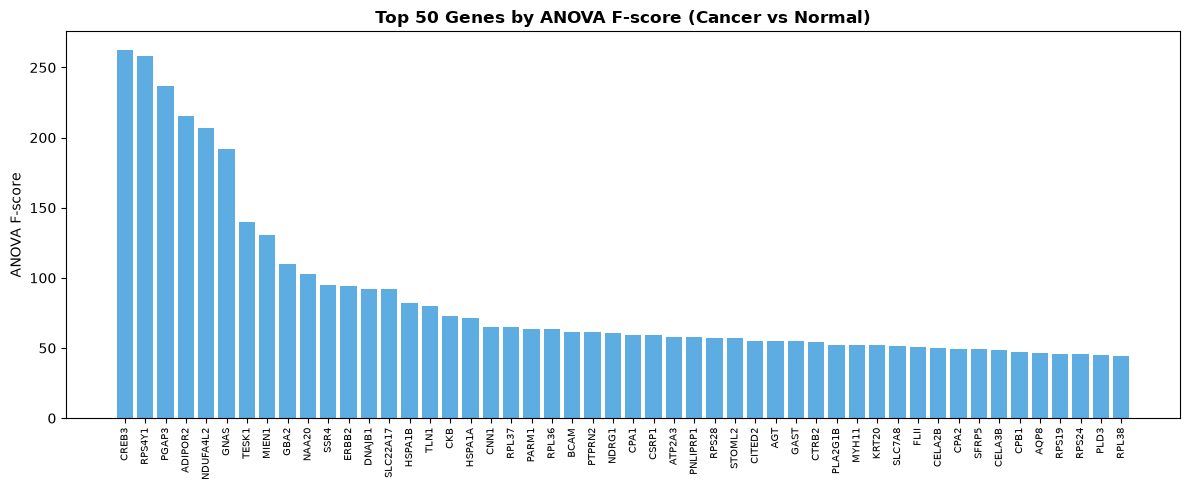

In [29]:
# ── 4d. Visualise top gene F-scores ──────────────────────────────────────
scores_df = pd.DataFrame({
    'gene'  : high_var_genes,
    'F_score': kbest.scores_
}).sort_values('F_score', ascending=False)

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(range(50), scores_df['F_score'].values[:50], color='#3498db', alpha=0.8)
ax.set_xticks(range(50))
ax.set_xticklabels(scores_df['gene'].values[:50], rotation=90, fontsize=7)
ax.set_ylabel('ANOVA F-score')
ax.set_title('Top 50 Genes by ANOVA F-score (Cancer vs Normal)', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'feature_selection_scores.png'), dpi=150)
plt.show()

In [30]:
# ── 4e. Apply selection to all matrices ───────────────────────────────────
# Only keep selected genes (where they exist in each dataset)

def apply_gene_selection(df, genes, name):
    available = [g for g in genes if g in df.columns]
    if len(available) < len(genes):
        print(f'  {name}: {len(genes)-len(available)} selected genes not present — using {len(available)}')
    return df[available]

tcga_final = apply_gene_selection(tcga_rna_norm, selected_genes, 'TCGA RNA')
gtex_final = apply_gene_selection(gtex_rna_norm, selected_genes, 'GTEx RNA')
geo_final  = apply_gene_selection(geo_rna_norm,  selected_genes, 'GEO RNA')

print(f'\nFinal selected shapes:')
print(f'  TCGA RNA : {tcga_final.shape}')
print(f'  GTEx RNA : {gtex_final.shape}')
print(f'  GEO RNA  : {geo_final.shape}')
print(f'  Mutation : {mutation_norm.shape}')
print(f'  Clinical : {clinical_encoded.shape}')


Final selected shapes:
  TCGA RNA : (183, 500)
  GTEx RNA : (362, 500)
  GEO RNA  : (293, 500)
  Mutation : (173, 6)
  Clinical : (1082, 186)


---
## 5. Build Survival Labels (for DeepSurv — Model 4)

Extract `days_to_death` and `vital_status` from clinical data to create survival targets.

In [31]:
print('Clinical column names (survival-related):')
surv_keywords = ['survival', 'death', 'vital', 'days', 'status', 'event']
surv_cols = [c for c in clinical.columns
             if any(kw in c.lower() for kw in surv_keywords)]
print(surv_cols)

print('\nFirst 5 rows of these columns:')
print(clinical[surv_cols].head())

Clinical column names (survival-related):
['cases.days_to_consent', 'cases.days_to_lost_to_followup', 'demographic.cause_of_death', 'demographic.cause_of_death_source', 'demographic.days_to_birth', 'demographic.days_to_death', 'demographic.marital_status', 'demographic.vital_status', 'demographic.year_of_death', 'diagnoses.days_to_best_overall_response', 'diagnoses.days_to_diagnosis', 'diagnoses.days_to_last_follow_up', 'diagnoses.days_to_last_known_disease_status', 'diagnoses.days_to_recurrence', 'diagnoses.last_known_disease_status', 'diagnoses.ovarian_specimen_status', 'diagnoses.peritoneal_fluid_cytological_status', 'treatments.days_to_treatment_end', 'treatments.days_to_treatment_start', 'treatments.initial_disease_status', 'treatments.margin_status']

First 5 rows of these columns:
  cases.days_to_consent cases.days_to_lost_to_followup  \
0                     0                            '--   
1                     0                            '--   
2                     0    

In [32]:
# ── Adjust column names below based on what your profiler showed ──────────
# Common TCGA column names:
#   'days_to_death', 'days_to_last_follow_up', 'vital_status'

DAYS_TO_DEATH_COL    = 'days_to_death'           # change if needed
DAYS_TO_FOLLOWUP_COL = 'days_to_last_follow_up'  # change if needed
VITAL_STATUS_COL     = 'vital_status'             # change if needed

surv_df = clinical[['case_submitter_id',
                     DAYS_TO_DEATH_COL,
                     DAYS_TO_FOLLOWUP_COL,
                     VITAL_STATUS_COL]].copy() if 'case_submitter_id' in clinical.columns else clinical.copy()

# Create unified duration: use days_to_death if dead, else days_to_last_follow_up
if DAYS_TO_DEATH_COL in surv_df.columns and DAYS_TO_FOLLOWUP_COL in surv_df.columns:
    surv_df['duration'] = surv_df[DAYS_TO_DEATH_COL].fillna(surv_df[DAYS_TO_FOLLOWUP_COL])
    surv_df['event']    = (surv_df[VITAL_STATUS_COL].astype(str).str.lower() == 'dead').astype(int)
    surv_df = surv_df[['duration', 'event']].dropna()
    print(f'Survival labels: {surv_df.shape}')
    print(f"Event distribution:\n{surv_df['event'].value_counts()}")
    print(f"Duration stats:\n{surv_df['duration'].describe()}")
else:
    print('WARNING: Survival columns not found with expected names.')
    print('Update DAYS_TO_DEATH_COL, DAYS_TO_FOLLOWUP_COL, VITAL_STATUS_COL above.')
    print(f'Available columns: {list(clinical.columns)}')

Update DAYS_TO_DEATH_COL, DAYS_TO_FOLLOWUP_COL, VITAL_STATUS_COL above.
Available columns: ['project.project_id', 'cases.case_id', 'cases.consent_type', 'cases.days_to_consent', 'cases.days_to_lost_to_followup', 'cases.disease_type', 'cases.index_date', 'cases.lost_to_followup', 'cases.primary_site', 'cases.submitter_id', 'demographic.age_at_index', 'demographic.age_is_obfuscated', 'demographic.cause_of_death', 'demographic.cause_of_death_source', 'demographic.country_of_birth', 'demographic.country_of_residence_at_enrollment', 'demographic.days_to_birth', 'demographic.days_to_death', 'demographic.demographic_id', 'demographic.education_level', 'demographic.ethnicity', 'demographic.gender', 'demographic.marital_status', 'demographic.occupation_duration_years', 'demographic.population_group', 'demographic.race', 'demographic.sex_at_birth', 'demographic.submitter_id', 'demographic.vital_status', 'demographic.year_of_birth', 'demographic.year_of_death', 'diagnoses.adrenal_hormone', 'diagn

---
## 6. Build Target Labels for All 4 Models

In [33]:
print('Stage/grade-related clinical columns:')
stage_cols = [c for c in clinical.columns
              if any(k in c.lower() for k in ['stage', 'grade', 'class', 'type'])]
print(stage_cols)
if stage_cols:
    print(clinical[stage_cols].head(10))

Stage/grade-related clinical columns:
['cases.consent_type', 'cases.disease_type', 'diagnoses.ajcc_clinical_stage', 'diagnoses.ajcc_pathologic_stage', 'diagnoses.ann_arbor_clinical_stage', 'diagnoses.ann_arbor_pathologic_stage', 'diagnoses.child_pugh_classification', 'diagnoses.classification_of_tumor', 'diagnoses.cog_liver_stage', 'diagnoses.cog_renal_stage', 'diagnoses.eln_risk_classification', 'diagnoses.enneking_msts_grade', 'diagnoses.enneking_msts_stage', 'diagnoses.ensat_pathologic_stage', 'diagnoses.figo_stage', 'diagnoses.gleason_grade_group', 'diagnoses.gleason_grade_tertiary', 'diagnoses.igcccg_stage', 'diagnoses.inpc_grade', 'diagnoses.inrg_stage', 'diagnoses.inss_stage', 'diagnoses.irs_stage', 'diagnoses.iss_stage', 'diagnoses.masaoka_stage', 'diagnoses.medulloblastoma_molecular_classification', 'diagnoses.primary_gleason_grade', 'diagnoses.secondary_gleason_grade', 'diagnoses.tumor_grade', 'diagnoses.tumor_grade_category', 'diagnoses.tumor_regression_grade', 'diagnoses.ui

In [34]:
# ── Model 1: Early Detection — Cancer(1) vs Normal(0) ─────────────────────
tcga_labels_series = pd.Series(1, index=tcga_final.index, name='cancer_label')
gtex_labels_series = pd.Series(0, index=gtex_final.index, name='cancer_label')
y_detection = pd.concat([tcga_labels_series, gtex_labels_series])
print(f'Model 1 (Early Detection) label counts:\n{y_detection.value_counts()}')

# ── Model 2: Stage Prediction — use AJCC stage or TNM stage ───────────────
# Look for a stage column in clinical data
# Common names: 'ajcc_pathologic_stage', 'tumor_stage', 'clinical_stage'
stage_col_candidates = [c for c in clinical.columns if 'stage' in c.lower()]
print(f'\nStage column candidates: {stage_col_candidates}')
if stage_col_candidates:
    STAGE_COL = stage_col_candidates[0]
    y_stage = clinical[STAGE_COL]
    print(f'Using: {STAGE_COL}')
    print(y_stage.value_counts())

# ── Model 3: Treatment Response — check if column exists ──────────────────
treat_cols = [c for c in clinical.columns
              if any(k in c.lower() for k in ['treatment', 'response', 'therapy', 'chemo'])]
print(f'\nTreatment response column candidates: {treat_cols}')

# ── Model 4: Survival — already created above in surv_df ──────────────────
print(f'\nModel 4 (Survival) labels ready: {surv_df.shape if "surv_df" in dir() else "see above"}')

Model 1 (Early Detection) label counts:
cancer_label
0    362
1    183
Name: count, dtype: int64

Stage column candidates: ['diagnoses.ajcc_clinical_stage', 'diagnoses.ajcc_pathologic_stage', 'diagnoses.ann_arbor_clinical_stage', 'diagnoses.ann_arbor_pathologic_stage', 'diagnoses.cog_liver_stage', 'diagnoses.cog_renal_stage', 'diagnoses.enneking_msts_stage', 'diagnoses.ensat_pathologic_stage', 'diagnoses.figo_stage', 'diagnoses.igcccg_stage', 'diagnoses.inrg_stage', 'diagnoses.inss_stage', 'diagnoses.irs_stage', 'diagnoses.iss_stage', 'diagnoses.masaoka_stage', 'diagnoses.uicc_clinical_stage', 'diagnoses.uicc_pathologic_stage']
Using: diagnoses.ajcc_clinical_stage
diagnoses.ajcc_clinical_stage
'--    1082
Name: count, dtype: int64

Treatment response column candidates: ['diagnoses.best_overall_response', 'diagnoses.days_to_best_overall_response', 'diagnoses.prior_treatment', 'treatments.chemo_concurrent_to_radiation', 'treatments.clinical_trial_indicator', 'treatments.course_number', '

---
## 7. Save All Preprocessed Files
All outputs go to `preprocessed/` folder — this is the input for the VAE notebook.

In [35]:
print('Saving preprocessed files...')

def save(df, name, out_dir=OUT_DIR):
    path = os.path.join(out_dir, f'{name}.csv')
    df.to_csv(path)
    size_mb = os.path.getsize(path) / 1024**2
    print(f'  Saved: {name}.csv  ({df.shape[0]}×{df.shape[1]}) — {size_mb:.2f} MB')

# RNA-Seq
save(tcga_final,        'tcga_rna_preprocessed')
save(gtex_final,        'gtex_rna_preprocessed')
save(geo_final,         'geo_rna_preprocessed')
save(tcga_bio_norm,     'tcga_biomarkers_preprocessed')

# Mutations
save(mutation_norm,     'mutation_matrix_preprocessed')

# Clinical
save(clinical_encoded,  'clinical_encoded')
clinical.to_csv(os.path.join(OUT_DIR, 'clinical_raw_clean.csv'))
print(f'  Saved: clinical_raw_clean.csv (for label extraction later)')

# Survival labels
if 'surv_df' in dir() and not surv_df.empty:
    save(surv_df, 'survival_labels')

# Early detection labels
y_detection.to_csv(os.path.join(OUT_DIR, 'y_detection.csv'), header=True)
print(f'  Saved: y_detection.csv')

# Selected gene list
pd.Series(selected_genes).to_csv(os.path.join(OUT_DIR, 'selected_genes.csv'), index=False, header=False)
print(f'  Saved: selected_genes.csv ({len(selected_genes)} genes)')

print(f'\nAll files saved to: {OUT_DIR}')

Saving preprocessed files...
  Saved: tcga_rna_preprocessed.csv  (183×500) — 1.73 MB
  Saved: gtex_rna_preprocessed.csv  (362×500) — 3.48 MB
  Saved: geo_rna_preprocessed.csv  (293×500) — 2.82 MB
  Saved: tcga_biomarkers_preprocessed.csv  (183×7) — 0.03 MB
  Saved: mutation_matrix_preprocessed.csv  (173×6) — 0.01 MB
  Saved: clinical_encoded.csv  (1082×186) — 1.61 MB
  Saved: clinical_raw_clean.csv (for label extraction later)
  Saved: survival_labels.csv  (1082×201) — 1.27 MB
  Saved: y_detection.csv
  Saved: selected_genes.csv (500 genes)

All files saved to: D:\CDAC_Project\PAN-DATASET\preprocessed


---
## 8. Final QC Summary

In [36]:
print('=' * 70)
print('PREPROCESSING COMPLETE — FINAL SUMMARY')
print('=' * 70)
print(f'\n  Output directory: {OUT_DIR}')
print(f'\n  Files produced:')
for f in sorted(os.listdir(OUT_DIR)):
    fpath = os.path.join(OUT_DIR, f)
    size  = os.path.getsize(fpath) / 1024**2
    print(f'    {f:<45} {size:.2f} MB')

print(f'\n  PIPELINE STAGES COMPLETED:')
print(f'    [1] Missing Value Handling  — KNN imputation (k=5), median/mode for clinical')
print(f'    [2] Batch Effect Correction — ComBat L/S correction across TCGA / GTEx / GEO')
print(f'    [3] Normalization           — log1p + StandardScaler for RNA; RobustScaler for mutations')
print(f'    [4] Feature Selection       — Variance filter + ANOVA F-score top-{K_GENES}')
print(f'\n  READY FOR: Step 3 — Variational Autoencoder (VAE)')
print('=' * 70)

PREPROCESSING COMPLETE — FINAL SUMMARY

  Output directory: D:\CDAC_Project\PAN-DATASET\preprocessed

  Files produced:
    clinical_encoded.csv                          1.61 MB
    clinical_raw_clean.csv                        1.27 MB
    feature_selection_scores.png                  0.07 MB
    geo_rna_preprocessed.csv                      2.82 MB
    gtex_rna_preprocessed.csv                     3.48 MB
    mutation_matrix_preprocessed.csv              0.01 MB
    normalization_qc.png                          0.06 MB
    pca_batch_correction_comparison.png           0.11 MB
    pca_before_batch_correction.png               0.06 MB
    selected_genes.csv                            0.00 MB
    survival_labels.csv                           1.27 MB
    tcga_biomarkers_preprocessed.csv              0.03 MB
    tcga_rna_preprocessed.csv                     1.73 MB
    y_detection.csv                               0.00 MB

  PIPELINE STAGES COMPLETED:
    [1] Missing Value Handling  — KNN 

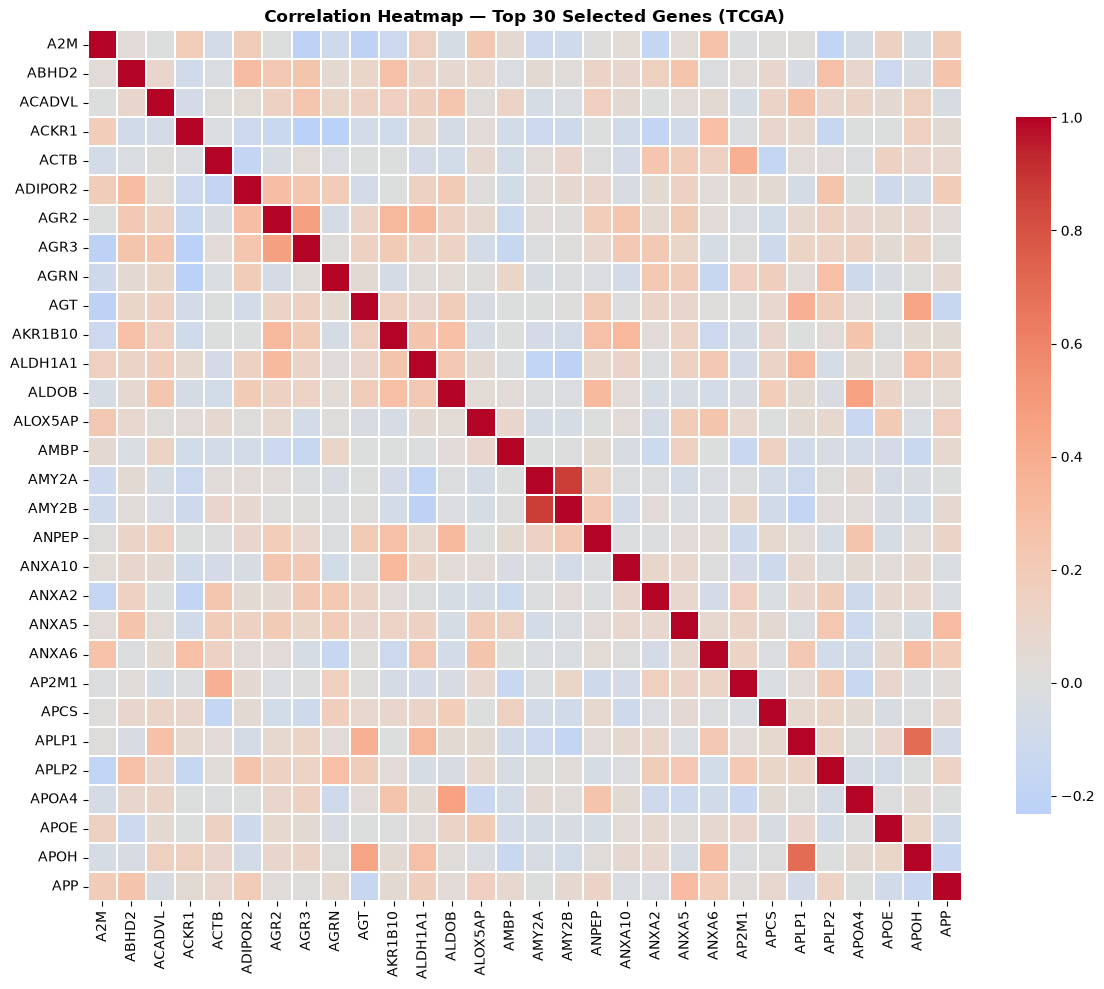

Saved: gene_correlation_heatmap.png

Preprocessing notebook complete.


In [37]:
# ── Final correlation heatmap of top selected genes ───────────────────────
top_genes = selected_genes[:30]
corr = tcga_final[top_genes].corr()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap='coolwarm', center=0, linewidths=0.3,
            annot=False, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Correlation Heatmap — Top 30 Selected Genes (TCGA)', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'gene_correlation_heatmap.png'), dpi=150)
plt.show()
print('Saved: gene_correlation_heatmap.png')
print('\nPreprocessing notebook complete.')